# A/B-тест платёжной формы: A — старая, B — новая

В проекте сравниваются старая и новая версии платёжной формы банковского приложения. Основная метрика — доля пользователей, завершивших оплату (`step4_success`), среди всех назначенных в эксперимент пользователей (ITT).

Дополнительно анализируется полная четырёхшаговая воронка: открытие формы → ввод данных → подтверждение → успешная оплата. Промежуточные этапы используются для диагностики поведения пользователей и поиска возможных точек оттока; они не заменяют основную метрику.

Успешная оплата определяется как наличие непустого `step4_success` хотя бы в одной платежной попытке пользователя. Интерпретация предполагает, что это поле действительно фиксирует завершённую оплату.

## Импорт библиотек

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.optimize import brentq
from statsmodels.stats.proportion import proportions_ztest, proportion_confint, proportion_effectsize
from statsmodels.stats.power import NormalIndPower

pd.set_option('display.max_columns', 100)
sns.set_theme(style='whitegrid')

## Настройки и загрузка данных

In [2]:
file_path = 'dannye.xlsx'  # Положите Excel-файл рядом с ноутбуком или укажите полный путь
users_raw = pd.read_excel(file_path, sheet_name='Пользователи')
payments_raw = pd.read_excel(file_path, sheet_name='Платежи')
ALPHA = 0.05
TARGET_POWER = 0.80
EXPECTED_SHARE_B = 0.50
MDE_ABSOLUTE = 0.02
BOOTSTRAP_ITERATIONS = 10_000
RANDOM_SEED = 42
print('Пользователей:', len(users_raw), '| строк платежей:', len(payments_raw))

Пользователей: 1504 | строк платежей: 2661


## Проверка структуры данных

In [3]:
required_users = {'user_id', 'group', 'age', 'city', 'device_type'}
required_payments = {'payment_id', 'user_id', 'step1_opened', 'step2_entered', 'step3_confirmed', 'step4_success'}
missing_users = required_users - set(users_raw.columns)
missing_payments = required_payments - set(payments_raw.columns)
display(users_raw.head())
display(payments_raw.head())

,user_id,group,age,city,device_type
0,1001,A,31,Москва,ios
1,1002,A,31,Москва,ios
2,1003,A,25,Москва,android
3,1004,A,20,Москва,ios
4,1005,A,34,Москва,ios


,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
0,5001,1001.0,A,2024-04-16 06:06:00,2024-04-16 06:10:00,NaT,NaT
1,5002,1002.0,A,2024-04-12 07:38:00,2024-04-12 07:41:00,NaT,NaT
2,5003,1003.0,A,2024-04-26 20:03:00,2024-04-26 20:07:00,NaT,NaT
3,5004,1004.0,A,2024-04-09 16:02:00,NaT,NaT,NaT
4,5005,1004.0,A,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00


## Очистка пользователей и аудит назначения в группы

В исходной таблице не обнаружено пользователей, одновременно назначенных в A и B, и повторных строк user_id. После удаления записей с некорректным возрастом в анализе осталось 1 501 пользователь: 751 в группе A и 750 в группе B.

Таким образом, очистка исключила 3 пользовательские записи. Для интерпретации результата важно, чтобы исключение по возрасту не зависело от варианта теста или вероятности оплаты.

In [4]:
users = users_raw.copy()
payments = payments_raw.copy()

users = users[users['user_id'].notna() & users['user_id'].astype(str).str.strip().ne('')]
users = users[users['group'].notna() & users['group'].astype(str).str.strip().ne('')]
users['group'] = users['group'].astype(str).str.strip().str.upper()

unexpected = set(users['group'].unique()) - {'A', 'B'}
if unexpected:
    warnings.warn(f'Неожиданные группы исключены: {unexpected}')
    users = users[users['group'].isin(['A', 'B'])].copy()

conflict = users.groupby('user_id')['group'].nunique()
conflict_ids = conflict[conflict > 1].index
print('Пользователей с назначением сразу в A и B:', len(conflict_ids))


duplicate_rows = users['user_id'].duplicated().sum()
print('Повторных строк user_id:', duplicate_rows)
users = users.drop_duplicates('user_id', keep='first').copy()

users['age'] = pd.to_numeric(users['age'], errors='coerce')
users = users[users['age'].between(18, 100)].copy()
for col in ['city', 'device_type']:
    users[col] = users[col].replace(r'^\s*$', np.nan, regex=True)

print('Пользователей после очистки:', len(users))
display(users['group'].value_counts().reindex(['A', 'B']).rename('users'))

Пользователей с назначением сразу в A и B: 0
Повторных строк user_id: 0
Пользователей после очистки: 1501


group
A    751
B    750
Name: users, dtype: int64

## Очистка платежей и присоединение группы

Дубликатов payment_id не обнаружено. После исключения платежей пользователей, не вошедших в очищенную пользовательскую выборку, и присоединения группы по user_id осталось 2 660 строк платежей.

Группа берётся из таблицы пользователей, а не из платежной таблицы: это позволяет использовать единое назначение варианта на уровне пользователя.

In [5]:
payments = payments[payments['user_id'].notna() & payments['user_id'].astype(str).str.strip().ne('')].copy()
print('Дубликатов payment_id:', payments['payment_id'].duplicated().sum())
payments = payments.drop_duplicates('payment_id', keep='first')
payments = payments[payments['user_id'].isin(set(users['user_id']))].copy()
payments = payments.drop(columns=['group'], errors='ignore')
payments = payments.merge(users[['user_id', 'group']], on='user_id', how='inner', validate='many_to_one')
print('Платежей после очистки:', len(payments))

Дубликатов payment_id: 0
Платежей после очистки: 2660


## SRM — проверка соответствия размеров групп ожидаемому распределению

При ожидаемом распределении 50/50 фактические размеры групп практически идентичны: A — 751, B — 750. SRM-тест дал p-value = 0,9794, то есть статистически значимого отклонения от ожидаемого распределения нет.

Это хороший диагностический результат: явного перекоса по численности не видно. Однако отсутствие SRM само по себе не доказывает, что рандомизация была реализована корректно.

In [6]:
sizes = users['group'].value_counts().reindex(['A', 'B'], fill_value=0)
if (sizes == 0).any():
    raise ValueError('Одна из групп A/B пуста.')
n_total = int(sizes.sum())
expected = np.array([n_total * (1 - EXPECTED_SHARE_B), n_total * EXPECTED_SHARE_B])
observed = sizes.to_numpy()
srm_chi2, srm_p = stats.chisquare(observed, f_exp=expected)
display(pd.DataFrame({'group': ['A', 'B'], 'observed': observed, 'expected': expected}))
print(f'SRM p-value = {srm_p:.6f}')
if srm_p < ALPHA:
    print('найдено значимое отклонение от ожидаемого распределения')

,group,observed,expected
0,A,751,750.5
1,B,750,750.5


SRM p-value = 0.979408


## Баланс исходных характеристик

Возраст групп близок: средний возраст — 32,74 года в A и 32,65 года в B; тест Уэлча не выявил различий (p = 0,8314). Распределение по городам также статистически значимо не различается (χ², p = 0,4404).

По типу устройства получено p = 0,0595. При уровне значимости 5% это не является статистически значимым различием, хотя наблюдается некоторое отличие в долях iOS и Android. Результат стоит учитывать как диагностический сигнал, но не трактовать как доказанный дисбаланс.

В целом по трём проверенным характеристикам выраженного дисбаланса не обнаружено. Эти проверки не исключают различий по факторам, которых нет в данных.

In [7]:
age_summary = users.groupby('group')['age'].agg(['count', 'mean', 'std', 'median']).reindex(['A', 'B'])
display(age_summary)
age_a = users.loc[users.group == 'A', 'age'].dropna()
age_b = users.loc[users.group == 'B', 'age'].dropna()
_, age_p = stats.ttest_ind(age_a, age_b, equal_var=False)
print(f'Welch t-test возраста: p-value={age_p:.6f}')

for col in ['city', 'device_type']:
    tab = pd.crosstab(users[col], users['group']).reindex(columns=['A', 'B'], fill_value=0)
    if tab.shape[0] > 1:
        chi2, p, dof, exp = stats.chi2_contingency(tab)
        print(f'{col}: chi-square p-value={p:.6f}; min expected={exp.min():.2f}')
    display(tab)

,count,mean,std,median
group,,,,
A,751,32.740346,7.815060,32.0
B,750,32.654667,7.775347,33.0


Welch t-test возраста: p-value=0.831421
city: chi-square p-value=0.440375; min expected=196.50


group,A,B
city,,
Москва,288,306
Регион,268,245
СПб,194,199


device_type: chi-square p-value=0.059506; min expected=362.26


group,A,B
device_type,,
android,407,369
ios,344,381


## Основная метрика: успешная оплата среди всех назначенных пользователей

В знаменатель включены все пользователи из таблицы назначения: 751 в A и 750 в B. Пользователь считается успешным, если хотя бы в одной его платежной записи step4_success не пуст.

В обеих группах форма была открыта всеми пользователями: 751 из 751 в A и 750 из 750 в B. Поэтому в этих данных конверсия среди назначенных совпадает с конверсией среди открывших форму. Это наблюдение относится именно к текущей выборке и не означает, что открытие формы всегда гарантировано в реальном продукте.

In [8]:
# Этап считается достигнутым, если событие зафиксировано хотя бы в одной платежной попытке пользователя.
step_columns = ['step1_opened', 'step2_entered', 'step3_confirmed', 'step4_success']
payment_flags = payments.groupby('user_id').agg(
    **{f'has_{step}': (step, lambda x: x.notna().any()) for step in step_columns},
    payment_attempts=('payment_id', 'nunique')
).reset_index()
user_level = users[['user_id', 'group']].merge(payment_flags, on='user_id', how='left', validate='one_to_one')
flag_columns = [f'has_{step}' for step in step_columns]
for col in flag_columns:
    user_level[col] = user_level[col].fillna(False).astype(bool)
user_level['payment_attempts'] = user_level['payment_attempts'].fillna(0).astype(int)
conversion = user_level.groupby('group').agg(
    assigned_users=('user_id', 'nunique'),
    opened_users=('has_step1_opened', 'sum'),
    entered_users=('has_step2_entered', 'sum'),
    confirmed_users=('has_step3_confirmed', 'sum'),
    successful_users=('has_step4_success', 'sum'),
    payment_attempts=('payment_attempts', 'sum')
).reindex(['A', 'B'])
stage_count_cols = ['assigned_users', 'opened_users', 'entered_users', 'confirmed_users', 'successful_users']
stage_names = ['Назначены в группу', 'Открыли форму', 'Ввели данные', 'Подтвердили', 'Успешно оплатили']
for col in stage_count_cols[1:]:
    conversion[f'{col}_rate'] = conversion[col] / conversion['assigned_users']
conversion['main_conversion'] = conversion['successful_users'] / conversion['assigned_users']
conversion['form_open_rate'] = conversion['opened_users'] / conversion['assigned_users']
conversion['success_among_openers'] = conversion['successful_users'] / conversion['opened_users'].replace(0, np.nan)
display(conversion[stage_count_cols + ['main_conversion', 'payment_attempts']])

,assigned_users,opened_users,entered_users,confirmed_users,successful_users,main_conversion,payment_attempts
group,,,,,,,
A,751,751,672,549,494,0.65779,1309
B,750,750,707,644,603,0.80400,1351


## Размер эффекта новой формы

Конверсия старой формы составляет 65,78% (494/751), новой — 80,40% (603/750).

Разница B − A равна +14,62 процентного пункта. Относительно базовой конверсии A это прирост примерно 22,23%. По точечной оценке эффект заметный и направлен в пользу новой формы. Сам по себе размер эффекта ещё не говорит о статистической надёжности — она проверяется далее.

In [9]:
n_a, n_b = map(int, conversion['assigned_users'])
success_a, success_b = map(int, conversion['successful_users'])
p_a, p_b = map(float, conversion['main_conversion'])

absolute_lift = p_b - p_a
relative_lift = p_b / p_a - 1 if p_a > 0 else np.nan

print(f'A — старая форма: {p_a:.2%} ({success_a}/{n_a})')
print(f'B — новая форма:  {p_b:.2%} ({success_b}/{n_b})')
print(f'Абсолютный эффект B − A: {absolute_lift*100:.2f} п.п.')
print(f'Относительный прирост: {relative_lift:.2%}' if pd.notna(relative_lift) else 'Относительный прирост не определён: CR группы A равна нулю.')

A — старая форма: 65.78% (494/751)
B — новая форма:  80.40% (603/750)
Абсолютный эффект B − A: 14.62 п.п.
Относительный прирост: 22.23%


## Статистическая проверка основной метрики

Двусторонний z-тест двух долей дал z = −6,3859 и p-value, отображаемое с шестью знаками после запятой как 0,000000 (то есть p-value меньше 0,000001, а не буквально равно нулю). Точный критерий Фишера также дал p-value меньше 0,000001.

Оба теста указывают на статистически значимое различие при α = 0,05. Знак статистики z зависит от порядка вычитания долей в реализации теста; направление эффекта следует читать по самим конверсиям: B выше A.

In [10]:
z_stat, z_p = proportions_ztest([success_a, success_b], [n_a, n_b], alternative='two-sided')
table = np.array([[success_a, n_a-success_a], [success_b, n_b-success_b]])
odds_ratio, fisher_p = stats.fisher_exact(table, alternative='two-sided')
expected_success = np.array([p_a*n_a, p_b*n_b])
expected_failure = np.array([(1-p_a)*n_a, (1-p_b)*n_b])

print(f'z = {z_stat:.4f}; z-test p-value = {z_p:.6f}')
print(f'Fisher exact p-value = {fisher_p:.6f}')

z = -6.3859; z-test p-value = 0.000000
Fisher exact p-value = 0.000000


## Bootstrap-доверительный интервал разницы конверсий

95%-й bootstrap-интервал для разницы B − A составляет от +10,36 до +19,02 п.п. Весь интервал находится выше нуля. Это согласуется с результатом z-теста: данные поддерживают положительную разницу в пользу новой формы.

Интервал отражает статистическую неопределённость оценки на данной выборке; он не устраняет возможные систематические ошибки в назначении вариантов, измерении оплаты или окне атрибуции.

In [11]:
rng = np.random.default_rng(RANDOM_SEED)
out_a = user_level.loc[user_level.group == 'A', 'has_step4_success'].astype(int).to_numpy()
out_b = user_level.loc[user_level.group == 'B', 'has_step4_success'].astype(int).to_numpy()

boot_diffs = np.empty(BOOTSTRAP_ITERATIONS)
for i in range(BOOTSTRAP_ITERATIONS):
    a = rng.choice(out_a, size=len(out_a), replace=True)
    b = rng.choice(out_b, size=len(out_b), replace=True)
    boot_diffs[i] = b.mean() - a.mean()

ci_low, ci_high = np.quantile(boot_diffs, [0.025, 0.975])
print(f'95% bootstrap CI для B − A: [{ci_low*100:.2f}; {ci_high*100:.2f}] п.п.')

95% bootstrap CI для B − A: [10.36; 19.02] п.п.


## Интервалы Wilson для конверсии каждой группы

95%-й интервал Wilson для конверсии A: 62,31–69,08%. Для B: 77,41–83,08%. Интервалы заметно разнесены, что визуально согласуется с оценкой более высокой конверсии в группе B.

Для прямой оценки разницы между группами более уместен bootstrap-интервал B − A, рассчитанный выше; интервалы Wilson здесь описывают неопределённость конверсии каждой группы отдельно.

In [12]:
ci_rows = []
for group, succ, total in [('A', success_a, n_a), ('B', success_b, n_b)]:
    lo, hi = proportion_confint(succ, total, alpha=ALPHA, method='wilson')
    ci_rows.append({'group': group, 'conversion': succ/total, 'ci_low': lo, 'ci_high': hi})
wilson = pd.DataFrame(ci_rows).set_index('group')
display(wilson)

,conversion,ci_low,ci_high
group,,,
A,0.65779,0.623131,0.690842
B,0.80400,0.774071,0.830831


## MDE и оценка достаточности выборки

При текущих размерах групп (751 и 750) расчётная минимальная обнаруживаемая разница для мощности 80% составляет примерно 6,67 п.п. Это приближённая оценка при базовой конверсии A и заданных α и мощности.

Если бы целью эксперимента было надёжно обнаруживать эффект всего 2 п.п., расчёт показывает потребность примерно в 8 711 пользователях в A и 8 699 в B. Текущая выборка существенно меньше этого ориентира.

Это не отменяет обнаруженный в данных крупный эффект (+14,62 п.п.), который статистически значим. Но тест не рассчитан на уверенное выявление небольших улучшений порядка 2 п.п.

In [13]:
power_model = NormalIndPower()
ratio = n_b / n_a

if 0 < p_a < 1:
    detectable_h = power_model.solve_power(
        effect_size=None, nobs1=n_a, alpha=ALPHA,
        power=TARGET_POWER, ratio=ratio, alternative='two-sided'
    )
    try:
        detectable_p = brentq(
            lambda p: proportion_effectsize(p, p_a) - detectable_h,
            p_a + 1e-8, 1-1e-8
        )
        print(f'Приближённый обнаруживаемый эффект при текущей выборке: {abs(detectable_p-p_a)*100:.2f} п.п.')
    except ValueError:
        print('Не удалось преобразовать MDE в вероятность для текущей базовой конверсии.')

    target_p = p_a + MDE_ABSOLUTE
    if 0 < target_p < 1:
        h = abs(proportion_effectsize(target_p, p_a))
        req_a = power_model.solve_power(
            effect_size=h, nobs1=None, alpha=ALPHA,
            power=TARGET_POWER, ratio=ratio, alternative='two-sided'
        )
        print(f'Для MDE={MDE_ABSOLUTE*100:.2f} п.п. и мощности {TARGET_POWER:.0%}:')
        print(f'Нужно примерно A={np.ceil(req_a):,.0f}, B={np.ceil(req_a*ratio):,.0f} пользователей.')
        print(f'Сейчас A={n_a:,}, B={n_b:,}.')
    else:
        print('Проверьте MDE_ABSOLUTE: p_A + MDE должно быть между 0 и 1.')
else:
    print('Для расчёта мощности базовая конверсия A должна быть между 0 и 1.')

Приближённый обнаруживаемый эффект при текущей выборке: 6.67 п.п.
Для MDE=2.00 п.п. и мощности 80%:
Нужно примерно A=8,711, B=8,699 пользователей.
Сейчас A=751, B=750.


## Вторичные метрики: четырёхшаговая воронка

Воронка построена по четырём событиям из листа `Платежи`: `step1_opened` — открытие формы, `step2_entered` — ввод данных, `step3_confirmed` — подтверждение, `step4_success` — успешная оплата. Пользователь считается достигшим этапа, если соответствующее событие зафиксировано хотя бы в одной его платёжной попытке.

В группе A этапы прошли 751, 672, 549 и 494 пользователя соответственно; в группе B — 750, 707, 644 и 603 пользователя. Кумулятивная конверсия считается от всех назначенных пользователей, а переходная — от пользователей, достигших предыдущего этапа.

По кумулятивной конверсии группа B опережает A на 4,79 п.п. на этапе ввода данных (94,27% против 89,48%) и на 12,76 п.п. на этапе подтверждения (85,87% против 73,10%). Финальная конверсия успешной оплаты выше на 14,62 п.п. (80,40% против 65,78%).

Переходные конверсии также выше в B: открытие → ввод — 94,27% против 89,48%; ввод → подтверждение — 91,09% против 81,70%; подтверждение → успешная оплата — 93,63% против 89,98%. Это указывает, что преимущество новой формы наблюдается на каждом переходе воронки, особенно между вводом данных и подтверждением.

Основная метрика эксперимента остаётся прежней — доля назначенных пользователей с успешной оплатой (`step4_success`). Промежуточные этапы используются как диагностические вторичные метрики и помогают локализовать участки, на которых различается поведение пользователей.


### Таблица и статистическое сравнение этапов

В таблице ниже для каждого этапа показаны абсолютное число пользователей, кумулятивная конверсия от исходно назначенной группы и переходная конверсия от предыдущего этапа. Для этапов «Ввели данные» и «Подтвердили» дополнительно выполнены сравнения долей между A и B; p-value скорректированы методом Холма для двух промежуточных проверок.

На этапе ввода данных конверсия составляет 89,5% в A и 94,3% в B (разница B − A: +4,79 п.п.; скорректированный p-value = 0,000692). На этапе подтверждения — 73,1% и 85,9% соответственно (разница: +12,76 п.п.; скорректированный p-value = 1,84 × 10⁻⁹). Оба промежуточных различия статистически значимы после поправки Холма.

Шаг 4 (`step4_success`) не включён в эту таблицу вторичных проверок, поскольку он является основной метрикой эксперимента и отдельно проверяется в основном статистическом разделе.


,assigned_users,opened_users,entered_users,confirmed_users,successful_users,assigned_users_share_of_assigned,assigned_users_from_previous,opened_users_share_of_assigned,opened_users_from_previous,entered_users_share_of_assigned,entered_users_from_previous,confirmed_users_share_of_assigned,confirmed_users_from_previous,successful_users_share_of_assigned,successful_users_from_previous
group,,,,,,,,,,,,,,,
A,751,751,672,549,494,1.0,1.0,1.0,1.0,0.894807,0.894807,0.731025,0.816964,0.65779,0.899818
B,750,750,707,644,603,1.0,1.0,1.0,1.0,0.942667,0.942667,0.858667,0.910891,0.80400,0.936335


,Этап,A,B,"Разница B − A, п.п.",p-value,p-value Holm
0,Ввели данные,672/751 (89.5%),707/750 (94.3%),4.785974,6.919989e-04,6.919989e-04
1,Подтвердили,549/751 (73.1%),644/750 (85.9%),12.764137,9.205306e-10,1.841061e-09


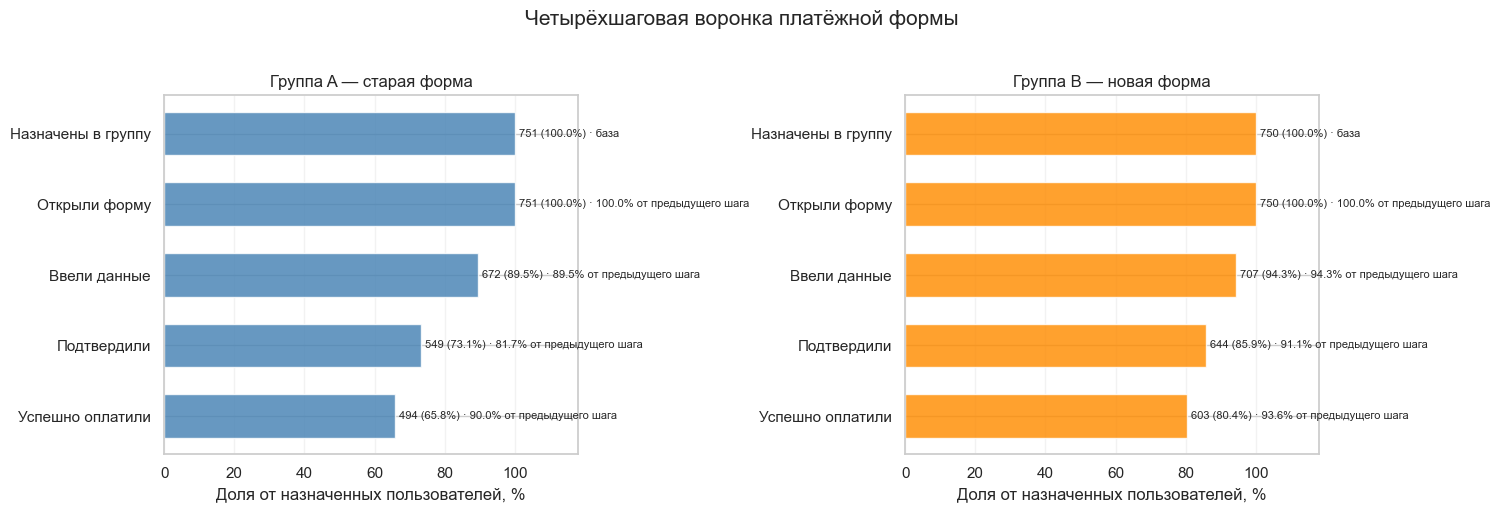

In [14]:
# Таблица воронки: абсолютные количества, кумулятивная и переходная конверсии.
funnel = conversion[stage_count_cols].copy()
for i, col in enumerate(stage_count_cols):
    funnel[f'{col}_share_of_assigned'] = funnel[col] / funnel['assigned_users']
    if i == 0:
        funnel[f'{col}_from_previous'] = 1.0
    else:
        previous_col = stage_count_cols[i - 1]
        funnel[f'{col}_from_previous'] = funnel[col] / funnel[previous_col].replace(0, np.nan)
display(funnel)

from statsmodels.stats.multitest import multipletests
stage_test_rows = []
for stage_label, col in [('Ввели данные', 'entered_users'), ('Подтвердили', 'confirmed_users')]:
    a_count = int(conversion.loc['A', col])
    b_count = int(conversion.loc['B', col])
    n_a_stage = int(conversion.loc['A', 'assigned_users'])
    n_b_stage = int(conversion.loc['B', 'assigned_users'])
    z_stage, p_stage = proportions_ztest([a_count, b_count], [n_a_stage, n_b_stage])
    stage_test_rows.append({
        'Этап': stage_label,
        'A': f'{a_count}/{n_a_stage} ({a_count/n_a_stage:.1%})',
        'B': f'{b_count}/{n_b_stage} ({b_count/n_b_stage:.1%})',
        'Разница B − A, п.п.': (b_count/n_b_stage-a_count/n_a_stage)*100,
        'p-value': p_stage
    })
stage_tests = pd.DataFrame(stage_test_rows)
stage_tests['p-value Holm'] = multipletests(stage_tests['p-value'], method='holm')[1]
display(stage_tests)

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharex=True)
colors = {'A': 'steelblue', 'B': 'darkorange'}
for ax, group in zip(axes, ['A', 'B']):
    row = conversion.loc[group]
    counts = [int(row[col]) for col in stage_count_cols]
    assigned = int(row['assigned_users'])
    cumulative = np.array(counts) / assigned * 100
    bars = ax.barh(np.arange(len(stage_names)), cumulative, color=colors[group], alpha=0.82, height=0.62)
    ax.set_yticks(np.arange(len(stage_names)), stage_names)
    ax.invert_yaxis()
    ax.set_xlim(0, 118)
    ax.set_xlabel('Доля от назначенных пользователей, %')
    ax.set_title(f'Группа {group} — ' + ('старая форма' if group == 'A' else 'новая форма'))
    ax.grid(axis='x', alpha=0.25)
    ax.set_axisbelow(True)
    for i, (bar, count, rate) in enumerate(zip(bars, counts, cumulative)):
        transition = 1.0 if i == 0 else counts[i] / counts[i-1] if counts[i-1] else np.nan
        transition_text = 'база' if i == 0 else (f'{transition:.1%} от предыдущего шага' if np.isfinite(transition) else 'нет данных')
        ax.text(min(rate + 1.2, 103), bar.get_y() + bar.get_height()/2,
                f'{count:,} ({rate:.1f}%) · {transition_text}', va='center', ha='left', fontsize=8)
fig.suptitle('Четырёхшаговая воронка платёжной формы', fontsize=15, y=1.02)
fig.tight_layout()
plt.show()

## График основной конверсии с интервалами Wilson

На графике сравниваются конверсии двух вариантов и 95%-е интервалы Wilson. Ожидаемо столбец B выше столбца A; интервалы групп не перекрываются. Это визуальное представление результата, а формальная проверка различия приведена в разделе статистического теста.

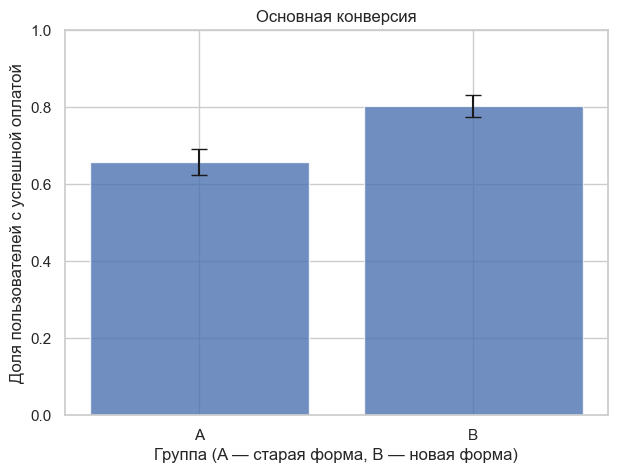

In [15]:
plot_df = wilson.reset_index()
y = plot_df['conversion'].to_numpy()
yerr = np.vstack([y - plot_df['ci_low'].to_numpy(), plot_df['ci_high'].to_numpy() - y])

plt.figure(figsize=(7, 5))
plt.bar(plot_df['group'], y, yerr=yerr, capsize=6, alpha=0.8)
plt.xlabel('Группа (A — старая форма, B — новая форма)')
plt.ylabel('Доля пользователей с успешной оплатой')
plt.title('Основная конверсия')
plt.ylim(0, min(1, max(plot_df['ci_high'].max()*1.25, 0.05)))
plt.show()

## Графики исходных характеристик и воронки

Графики позволяют визуально проверить распределения возраста, города и устройства между группами. Они дополняют тесты баланса из раздела 7, но не заменяют их.

По численным проверкам возраст и город не показали значимых различий; по устройствам p-value близок к порогу 0,05, но остаётся выше него. Поэтому график устройств стоит рассматривать вместе с этим результатом, не делая вывода о доказанном дисбалансе.

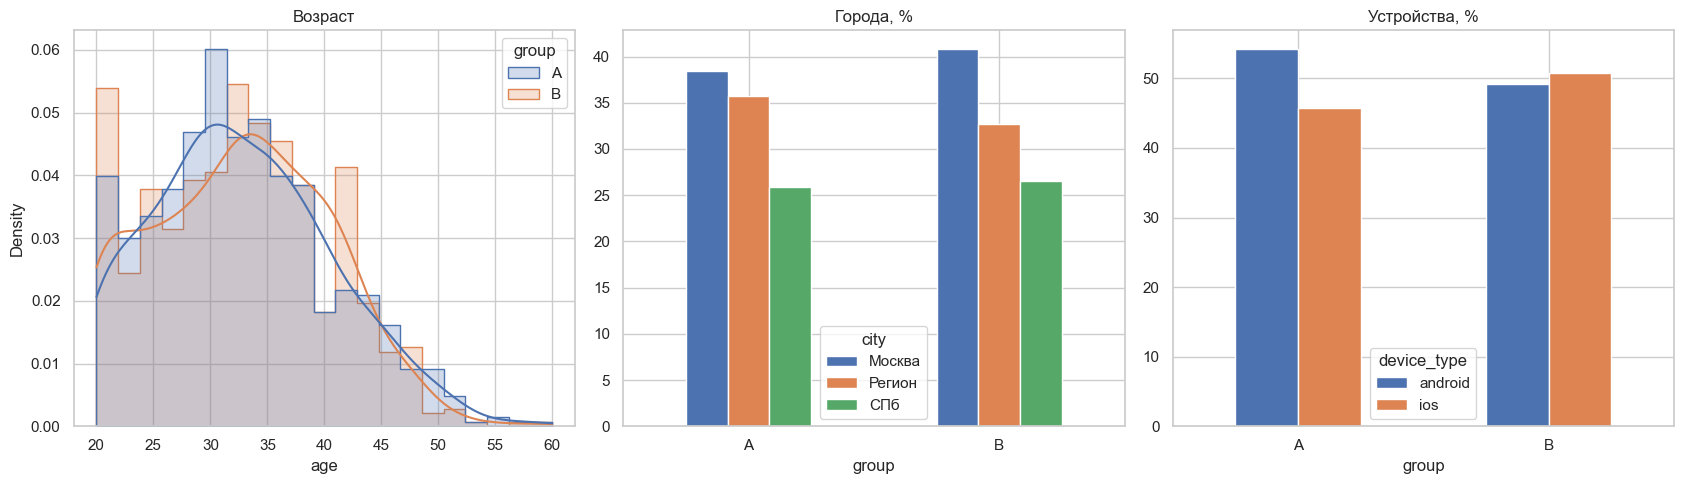

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
sns.histplot(data=users, x='age', hue='group', stat='density',
             common_norm=False, kde=True, element='step', ax=axes[0])
axes[0].set_title('Возраст')

pd.crosstab(users['group'], users['city'], normalize='index').mul(100).plot(kind='bar', ax=axes[1])
axes[1].set_title('Города, %')
axes[1].tick_params(axis='x', rotation=0)

pd.crosstab(users['group'], users['device_type'], normalize='index').mul(100).plot(kind='bar', ax=axes[2])
axes[2].set_title('Устройства, %')
axes[2].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

## Итоговая интерпретация

Основная метрика — доля пользователей с зафиксированной успешной оплатой (`step4_success`) среди всех назначенных в группы. В группе A успешно оплатили 494 из 751 пользователей (65,78%), в группе B — 603 из 750 (80,40%). Разница B − A составляет +14,62 процентного пункта, относительный прирост — 22,23%. Различие статистически значимо (двусторонний z-тест и точный критерий Фишера: p-value < 0,001); 95%-й bootstrap-интервал для разницы составляет от +10,36 до +19,02 п.п. По этим данным новая форма связана с более высокой конверсией в успешную оплату.

Четырёхшаговая воронка помогает понять, где формируется преимущество B. Открытие формы составляет 100% в обеих группах. На этапе ввода данных кумулятивная конверсия равна 89,48% в A и 94,27% в B; на этапе подтверждения — 73,10% и 85,87%; на этапе успешной оплаты — 65,78% и 80,40%. Переходные конверсии между соседними этапами также выше в B: 94,27% против 89,48% (открытие → ввод), 91,09% против 81,70% (ввод → подтверждение) и 93,63% против 89,98% (подтверждение → успешная оплата). Наибольшая разница между группами по кумулятивной конверсии среди промежуточных этапов наблюдается на подтверждении.

Сравнения промежуточных этапов подтверждают статистически значимые различия: после поправки Холма p-value составляет 0,000692 для ввода данных и 1,84 × 10⁻⁹ для подтверждения. Эти результаты являются диагностическими вторичными метриками; основное решение об эффекте эксперимента опирается на заранее выбранную метрику успешной оплаты.

Перед принятием решения о полном запуске следует убедиться, что события всех четырёх шагов одинаково и корректно логируются в обоих вариантах, а пользователи имеют сопоставимое окно наблюдения.